# 51 — Thesis figures, Part IV (Evolution of the design space)

This notebook draws every figure and table of this part of the thesis and writes them, as PDF (for the thesis), PNG and CSV, to
`thesis_figures_v2/Part_IV_design_space_evolution/<group>/<role>/`. Run it top to bottom; every cell shows exactly the file that was written.

| group | role | file | kind | what it shows |
|---|---|---|---|---|
| IV1. Layout convergence | main | `q6_leading_layout_by_architecture` | figure | Layouts inside the three largest architectures |
| IV1. Layout convergence | appendix | `q6_architecture_centres_tilting_units` | figure | Architecture centres in tilting sets and propulsor units |
| IV1. Layout convergence | appendix | `q6_tp_units_by_tilting_sets` | figure | Tilt Propulsor units by tilting sets |
| IV2. Attributes and drivers | appendix | `q6_cvt_units_on_booms` | figure | CVT designs with propulsor units on booms |
| IV2. Attributes and drivers | appendix | `q6_boom_share_by_architecture` | figure | Propulsor units on booms per architecture |
| IV2. Attributes and drivers | appendix | `q6_ducted_share_by_architecture` | figure | Ducted propulsor unit per architecture |
| IV2. Attributes and drivers | appendix | `q6_cvt_ducted_by_boom_layout` | figure | CVT ducting inside each boom layout |
| IV2. Attributes and drivers | appendix | `q6_tilt_mechanisms_per_propulsor` | figure | Tilt mechanisms per propulsor unit |
| IV3. Centre and disparity | main | `q6_centroid_dispersion` | figure | Distance between cohorts and dispersion within them |

**Roles:** *main* goes in the chapter, *auxiliary* backs a statement of the chapter, *appendix* goes to the appendix.

## Where the numbers come from

- **The patent dataset** (627 designs): the author's characterisation of the patent drawings, read through `viz/thesis_q6.py` (the frames and builders of the seven existing figures, run unchanged and only relabelled and restyled; frame `cf` for the two new ones), `lib/drivers.py` (Spearman test), `lib/dominant_design.py` (Rao's Q, permutation band) and `viz/frames.py` (Gower distance, subsystem weights). This notebook only draws.
- No external input.
- **Terms used in the figures:** architecture, cohort (a window of priority years), configuration; Tilt Propulsor, CVT (combined vectored thrust), Tilt Wing. ρ and p are Spearman against the priority year, every year to 2023. Distance of a cohort from the first = mean Gower distance between the designs of the two cohorts minus the mean of their two Rao's Q; band = 200 shuffles of designs across cohorts (seed 42, cohort sizes kept), 2.5th to 97.5th percentile.

## Look and layout rules

Every figure is drawn under the author's thesis style, `viz/part1.mplstyle` (style 1, chosen 2026-10-12 among five in `viz/style_options/`):
Arial-type sans (Liberation Sans here), 9 pt labels, 8 pt ticks and legends, no top or right frame, a light horizontal grid, 6.3 in wide, PDF with embedded fonts.

The rules each figure is held to, and checked against in this notebook (`viz/figcheck.py`):

1. **No text on top of other text or of a mark.** Checked automatically: the check table at the end must read 0.
2. **Anything in columns is placed at fixed positions, never padded with spaces** (for example a numbered key), so rows line up exactly.
3. **One grid per plot**: a right-hand second axis draws no grid of its own.
4. **Words, not codes**: every abbreviation in a figure is spelled out in the figure or its key.
5. **No title inside the figure**: the caption in the thesis carries it.
6. **Nothing under 6.5 pt** at print size. Checked automatically.

## Setup

In [1]:
import sys, pathlib, importlib
PILLAR = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(PILLAR))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from viz import config, thesis, figcheck
v2 = importlib.import_module('viz.thesis_v2_part4')
cfg = config.load()
ctx = thesis.context(cfg)
OUT = v2.out_root(cfg)
print(len(ctx.v), 'designs | external inputs:', cfg.analysis.get('external_inputs', 'script'), '| writing to', OUT)
CHECKS = []

def show(name):
    """Build the item once under the thesis style, write it, check its layout, and show the written file."""
    it = next(i for i in v2.ITEMS if i['name'] == name)
    obj, data = v2.save_v2_item(it, cfg, ctx)
    folder = OUT / it['group'] / it['role']
    if it['kind'] == 'figure':
        ov, small = figcheck.overlaps(obj), figcheck.small_text(obj)
        CHECKS.append({'file': name, 'group': it['group'], 'role': it['role'], 'text over text': len(ov), 'under 6.5 pt': len(small),
                       'problems': '; '.join(f'{a} | {b}' for a, b in ov[:3])})
        plt.close('all')
        display(Image(filename=str(folder / f'{name}.png'), width=760))
        print(('layout OK' if not ov and not small else f'CHECK: {len(ov)} overlaps, {len(small)} small texts {ov[:3]} {small[:3]}'),
              '|', folder / f'{name}.pdf')
    else:
        CHECKS.append({'file': name, 'group': it['group'], 'role': it['role'], 'text over text': '', 'under 6.5 pt': '', 'problems': 'table'})
        display(obj)
        print(folder / f'{name}.csv')

627 designs | external inputs: script | writing to /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution


/home/vasco/Vasco Workspace/Tese_Vasco_Lnx/eVTOL-Visual-Evaluation/labeling_evaluation/viz/frames.py:544: UserWarning: rapidfuzz not installed — fuzzy company matching disabled. Only exact lookup table matches will be applied.
  canon = g._normalise_company(sraw)


## IV1. Layout convergence

*Does each architecture converge on one layout?*

### Layouts inside the three largest architectures

`q6_leading_layout_by_architecture` · main · figure · from v2 of q6_leading_layout_by_class (Figure 13 (ii))

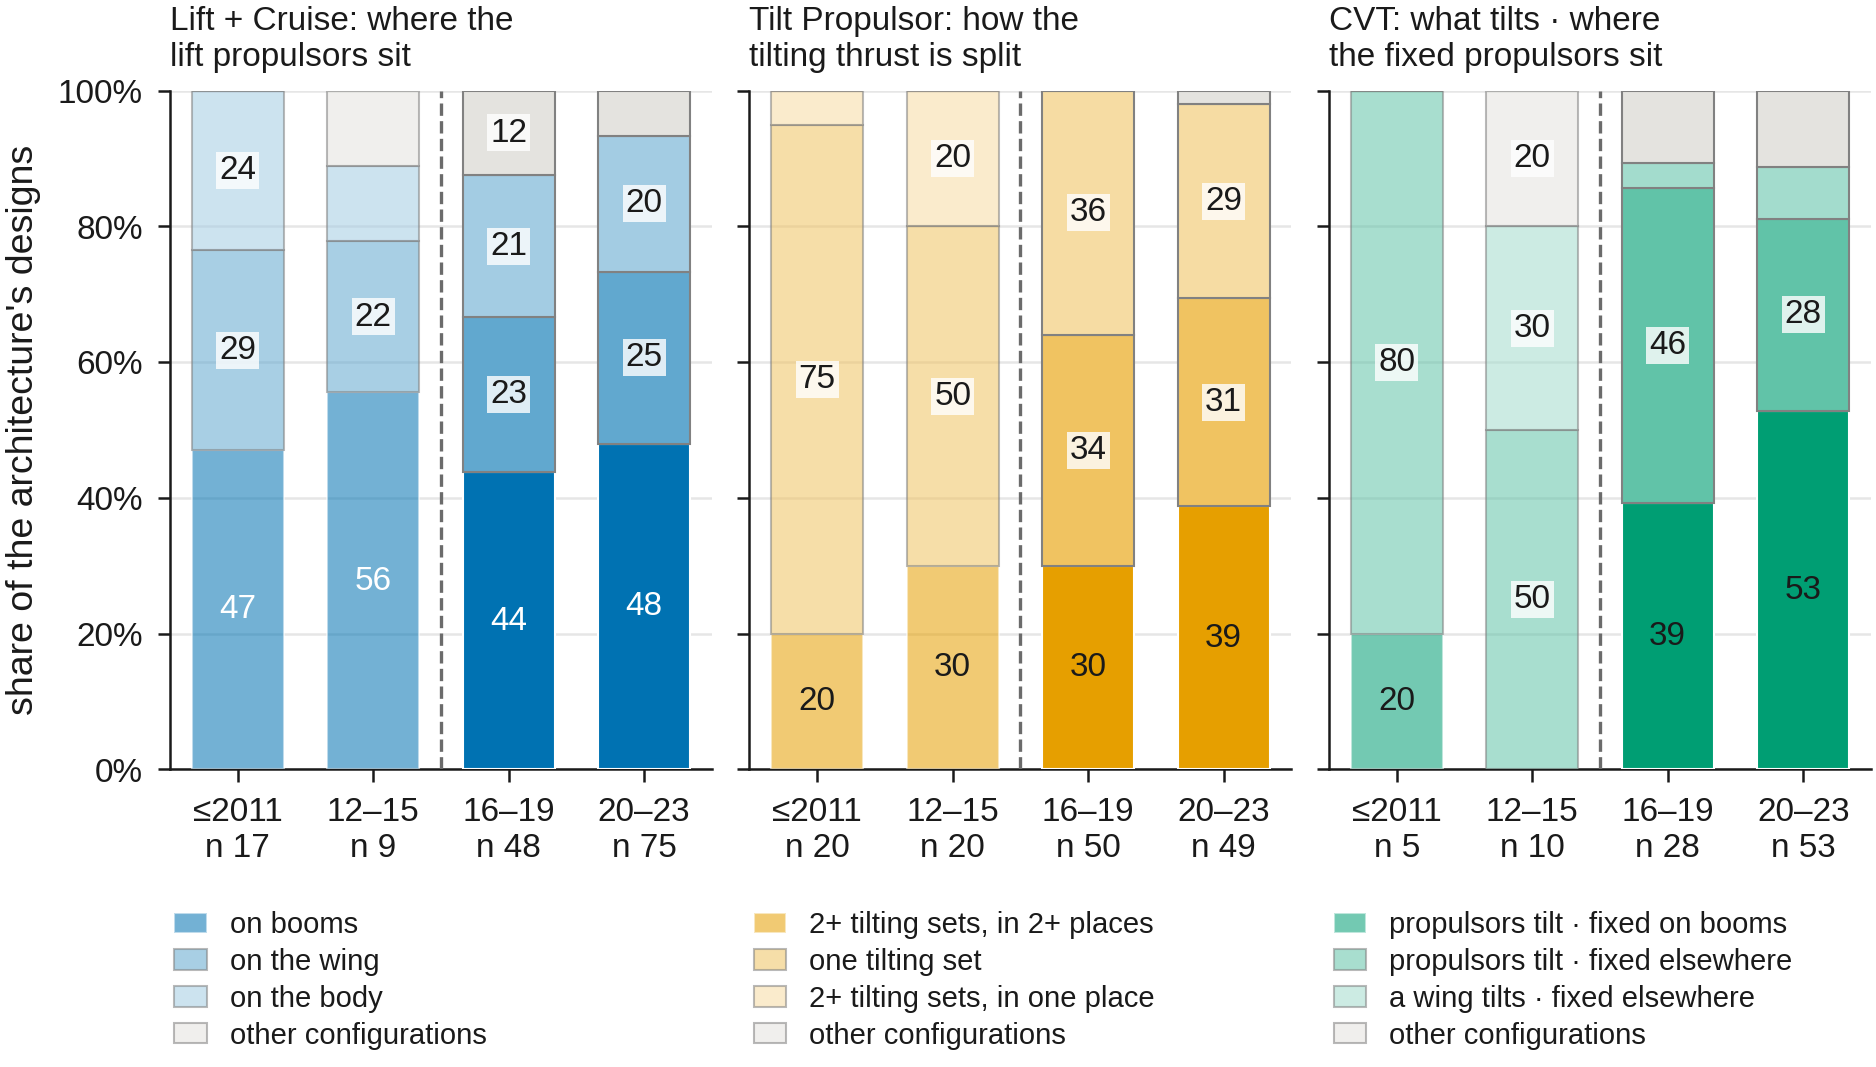

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV1_layout_convergence/main/q6_leading_layout_by_architecture.pdf


In [2]:
show('q6_leading_layout_by_architecture')

### Architecture centres in tilting sets and propulsor units

`q6_architecture_centres_tilting_units` · appendix · figure · from v2 of q6_class_centres_tilting_units (Figure 14 (i))

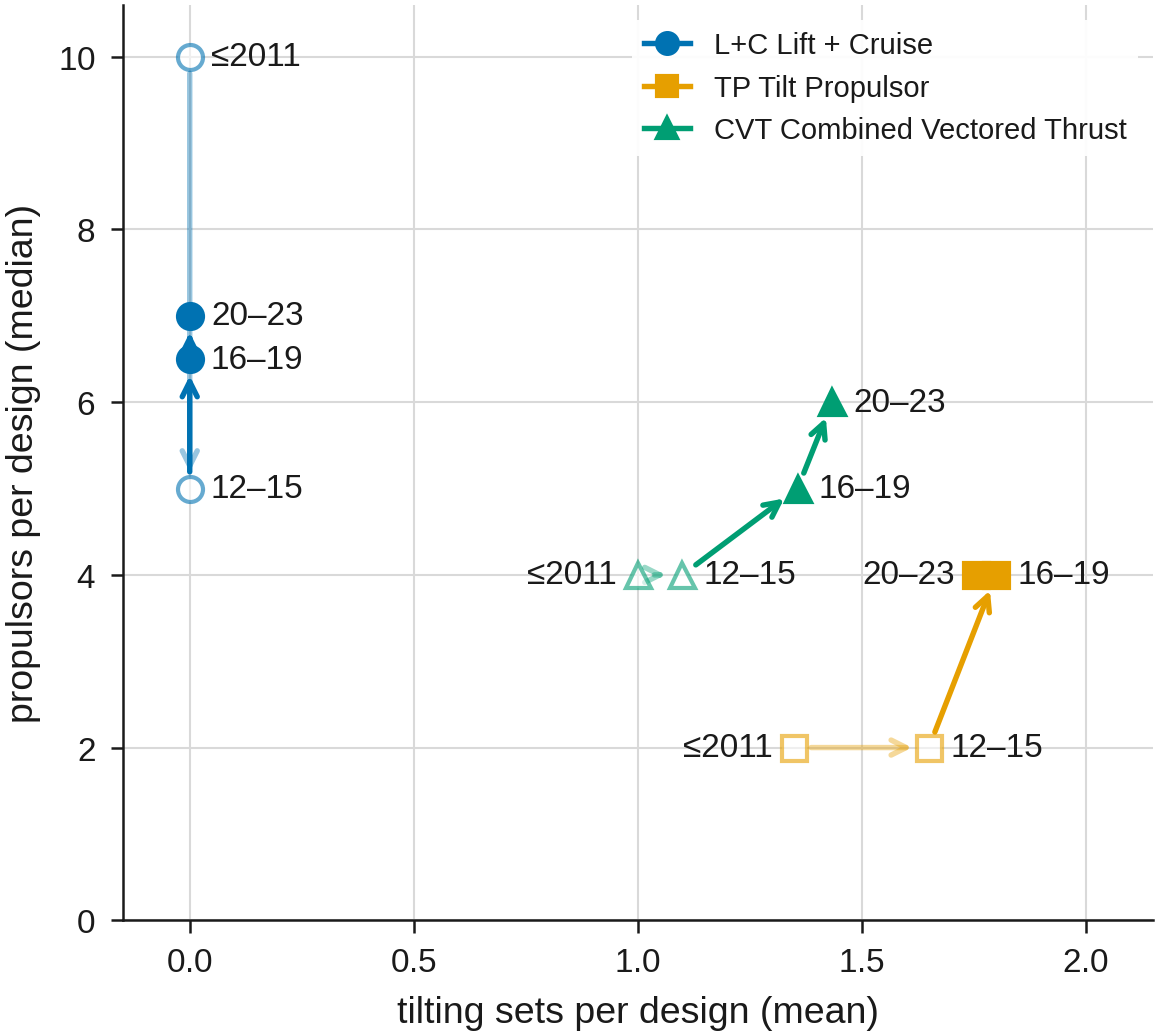

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV1_layout_convergence/appendix/q6_architecture_centres_tilting_units.pdf


In [3]:
show('q6_architecture_centres_tilting_units')

### Tilt Propulsor units by tilting sets

`q6_tp_units_by_tilting_sets` · appendix · figure · from v2 of q6_tp_units_by_tilting_sets (Figure 14 (ii))

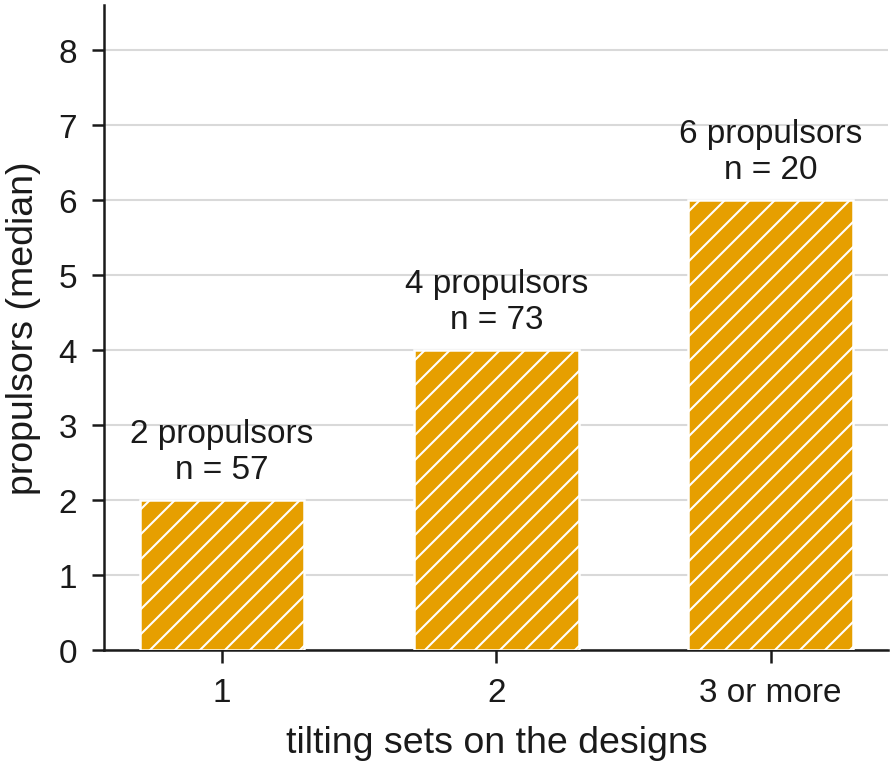

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV1_layout_convergence/appendix/q6_tp_units_by_tilting_sets.pdf


In [4]:
show('q6_tp_units_by_tilting_sets')

## IV2. Attributes and drivers

*Which attributes change, and which design drivers explain the change?*

### CVT designs with propulsor units on booms

`q6_cvt_units_on_booms` · appendix · figure · from v2 of q6_cvt_units_on_booms (Figure 14 (iii))

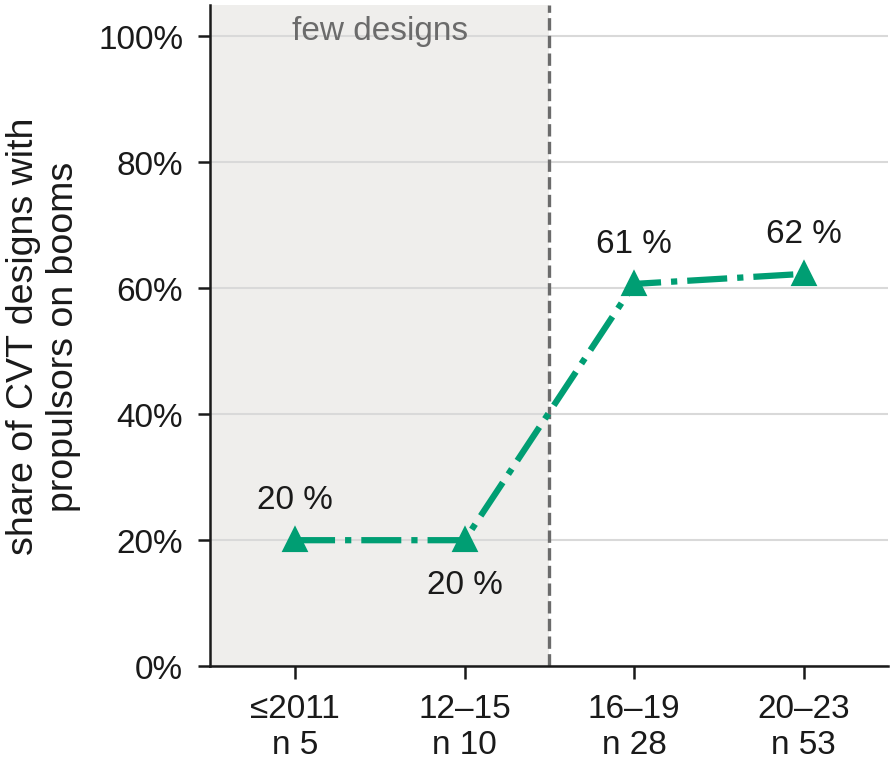

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV2_attributes_and_drivers/appendix/q6_cvt_units_on_booms.pdf


In [5]:
show('q6_cvt_units_on_booms')

### Propulsor units on booms per architecture

`q6_boom_share_by_architecture` · appendix · figure · from v2 of q6_boom_share_by_class (Figure 15 (i))

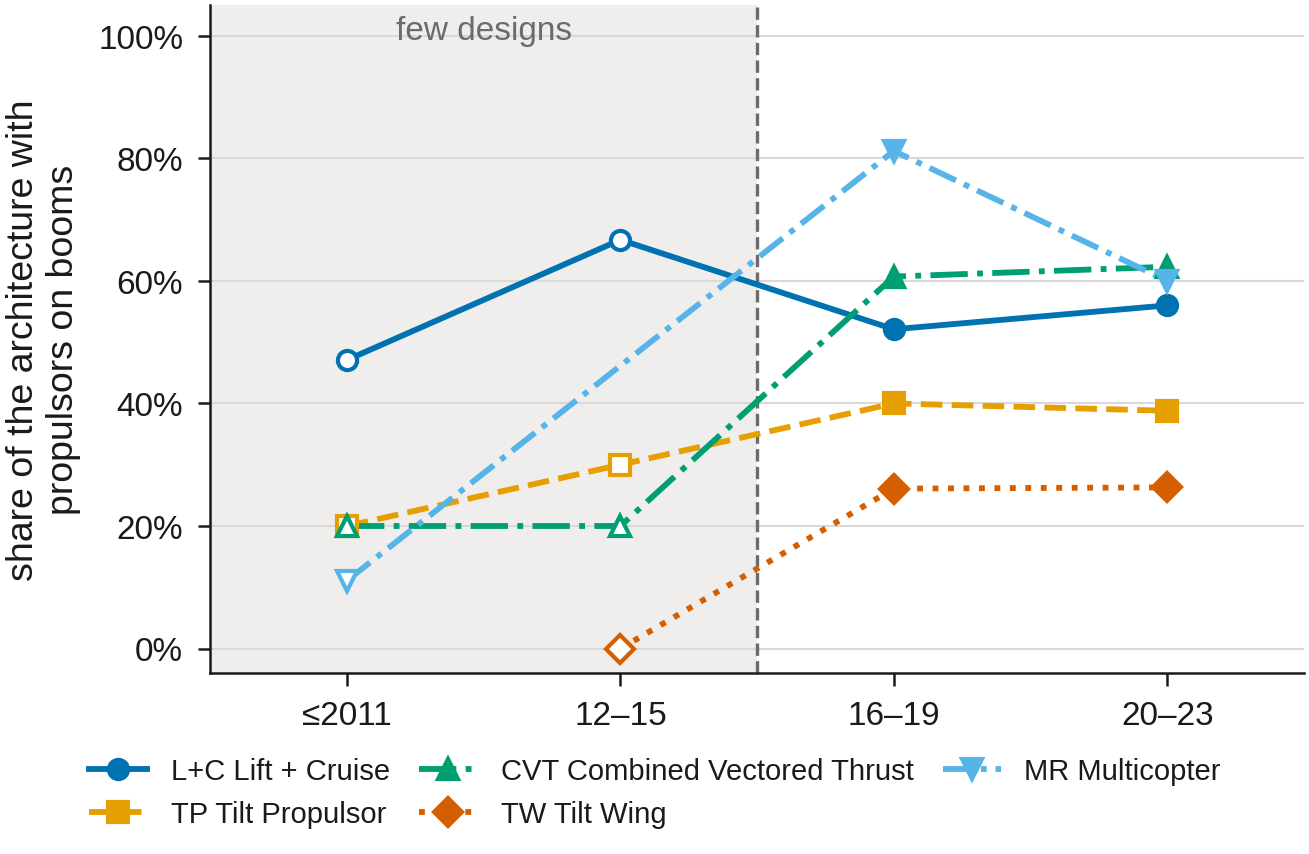

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV2_attributes_and_drivers/appendix/q6_boom_share_by_architecture.pdf


In [6]:
show('q6_boom_share_by_architecture')

### Ducted propulsor unit per architecture

`q6_ducted_share_by_architecture` · appendix · figure · from v2 of q6_ducted_share_by_class (Figure 15 (ii))

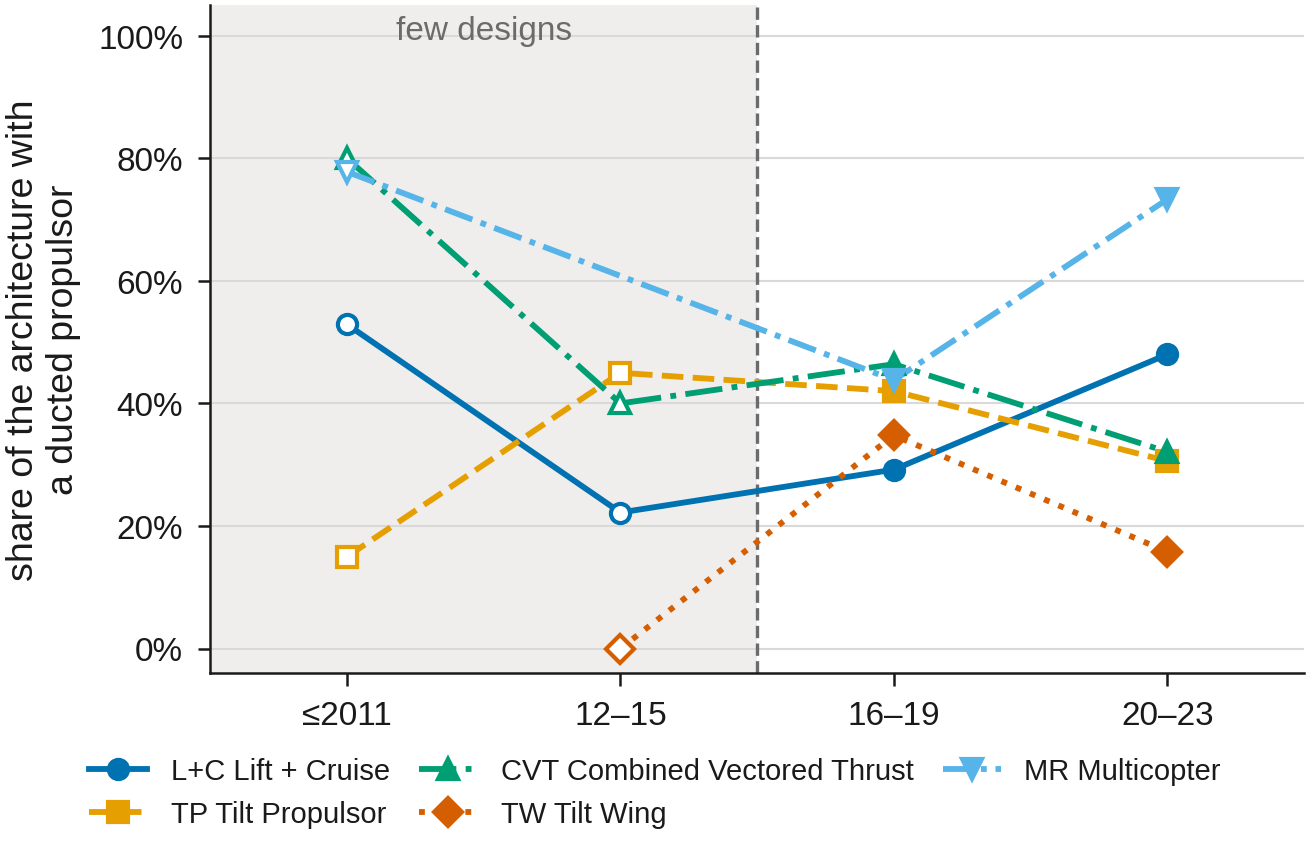

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV2_attributes_and_drivers/appendix/q6_ducted_share_by_architecture.pdf


In [7]:
show('q6_ducted_share_by_architecture')

### CVT ducting inside each boom layout

`q6_cvt_ducted_by_boom_layout` · appendix · figure · from v2 of q6_cvt_ducted_by_boom_layout (Figure 14 (iv))

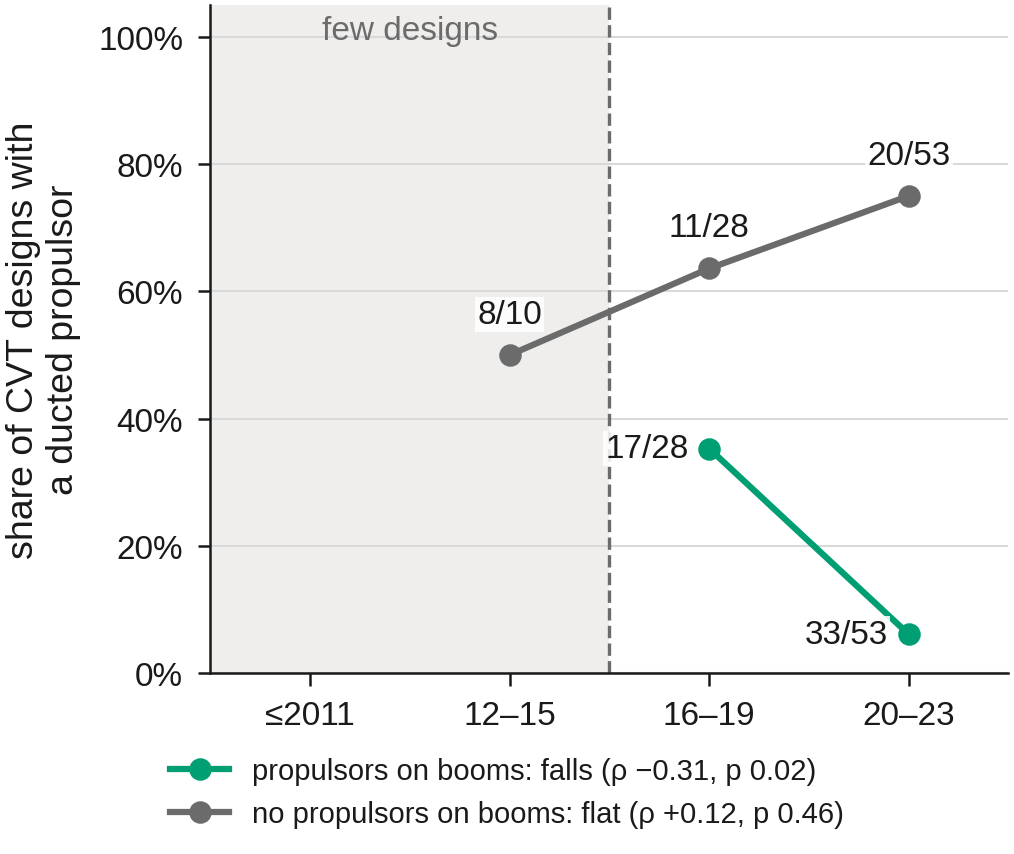

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV2_attributes_and_drivers/appendix/q6_cvt_ducted_by_boom_layout.pdf


In [8]:
show('q6_cvt_ducted_by_boom_layout')

### Tilt mechanisms per propulsor unit

`q6_tilt_mechanisms_per_propulsor` · appendix · figure · from new (Analysis IV)

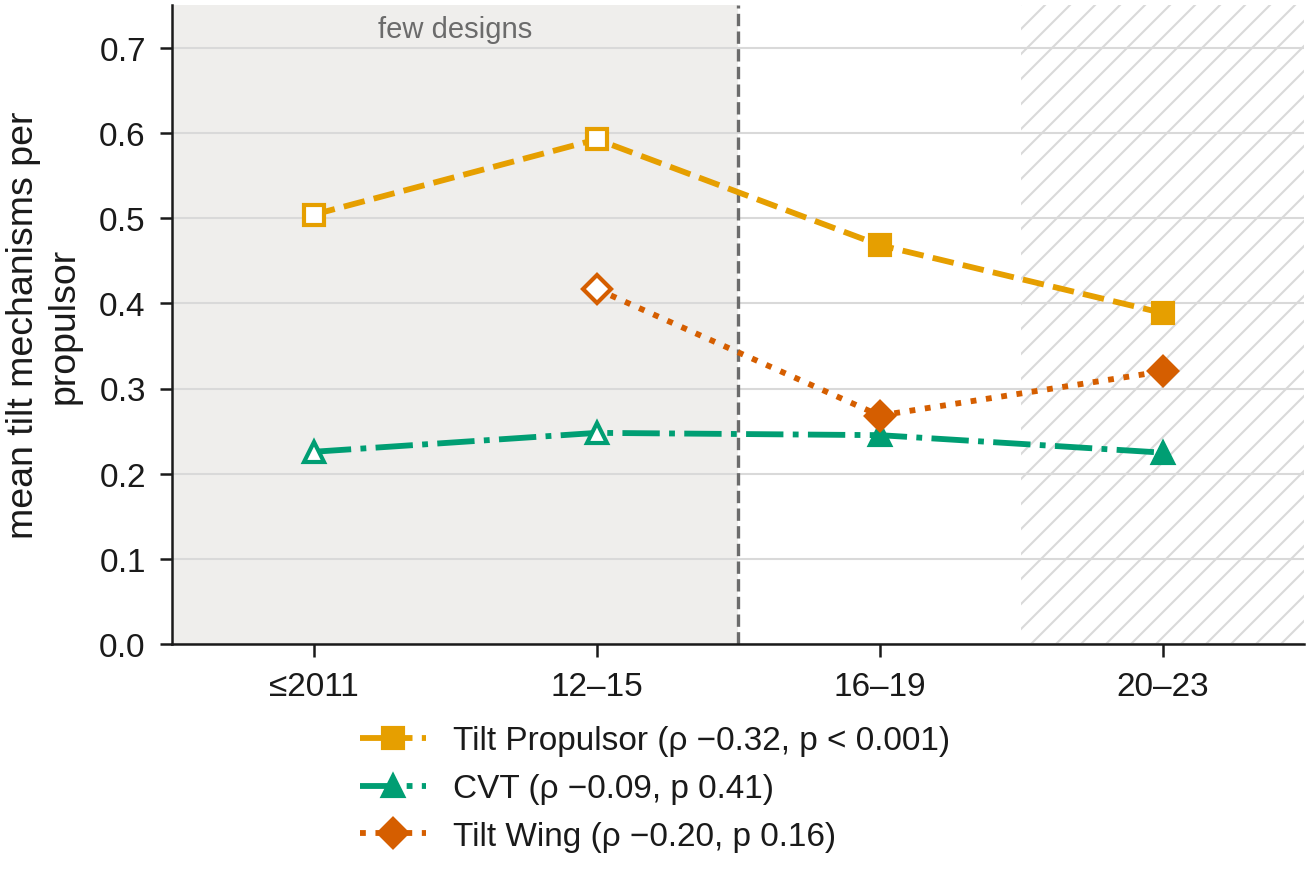

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV2_attributes_and_drivers/appendix/q6_tilt_mechanisms_per_propulsor.pdf


In [9]:
show('q6_tilt_mechanisms_per_propulsor')

## IV3. Centre and disparity

*Does the centre of the design space move while disparity holds?*

### Distance between cohorts and dispersion within them

`q6_centroid_dispersion` · main · figure · from new (Analysis IV)

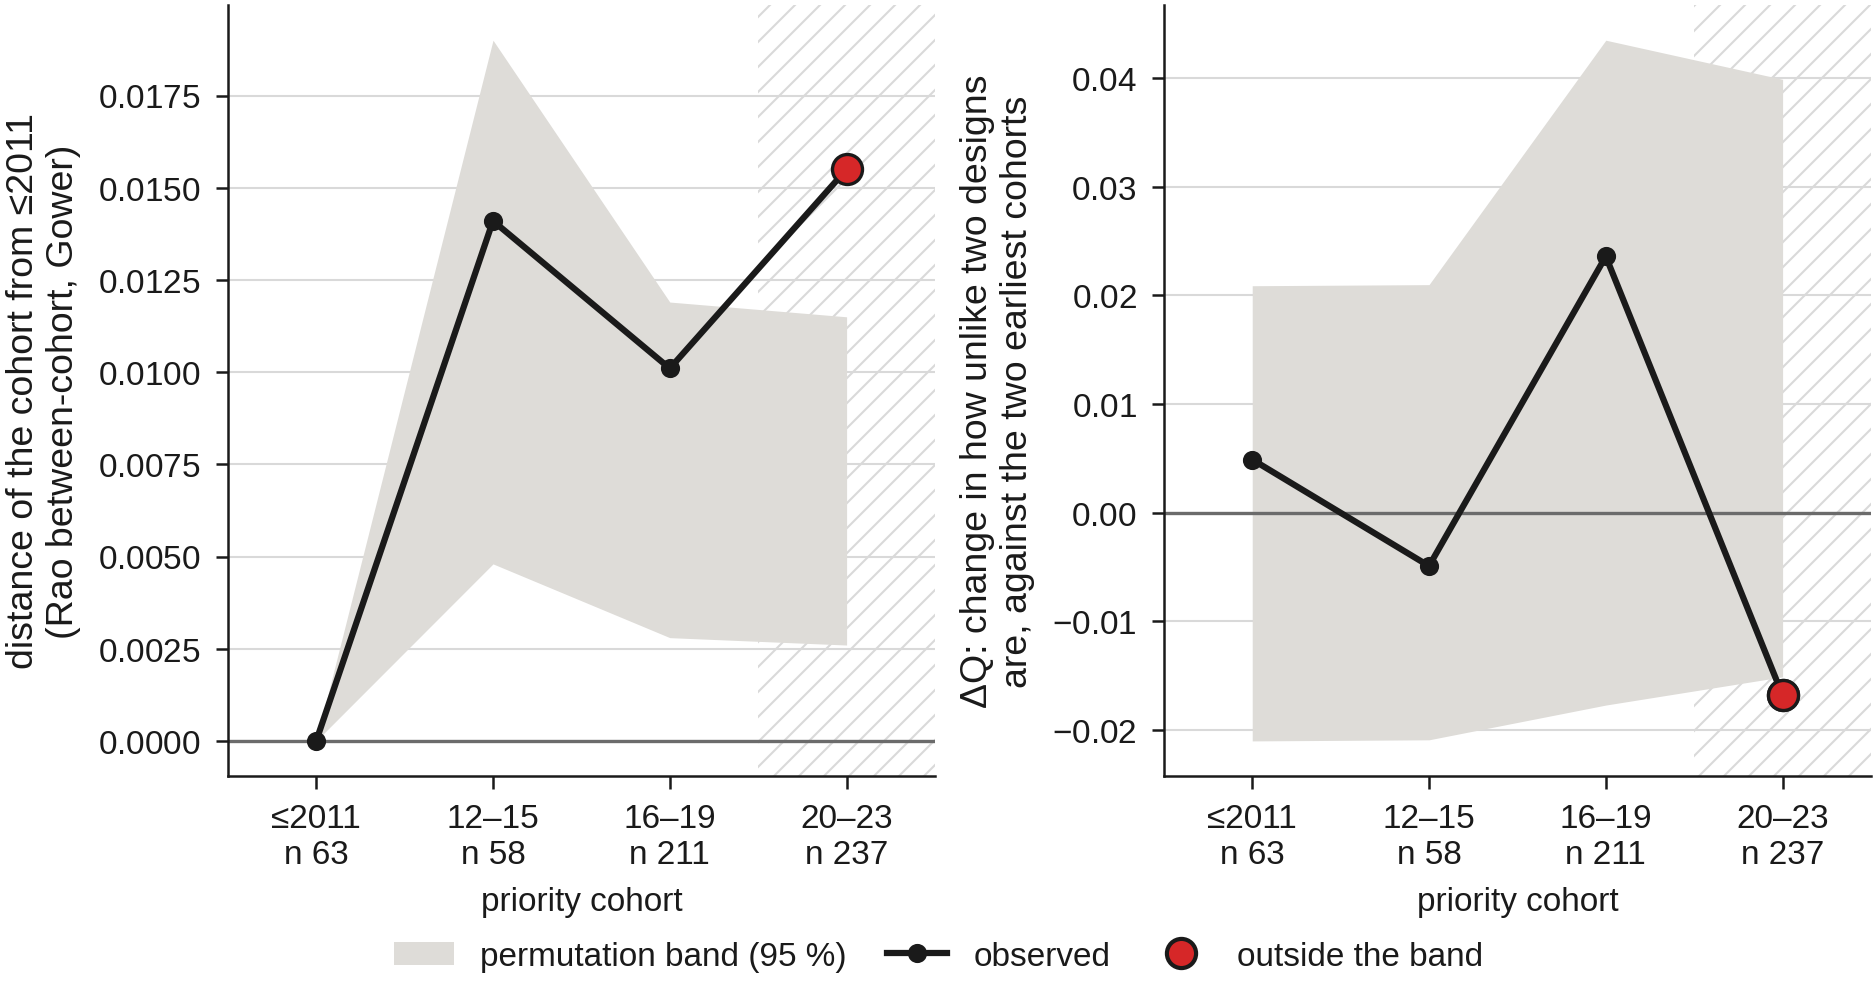

layout OK | /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution/IV3_centre_and_disparity/main/q6_centroid_dispersion.pdf


In [10]:
show('q6_centroid_dispersion')

## Numbers for the text

Recomputed from the same frames the figures draw; nothing typed. The *QUOTED* blocks are the numbers the thesis text states, each with the text's value in its heading.

In [11]:
from viz import thesis_v2_part4 as p4
for k, val in p4.numbers(ctx).items():
    print('\n' + k)
    print(val.to_string() if hasattr(val, 'to_string') else val)


pooled mean tilt mechanisms per propulsor unit, three architectures
window
<= 2011    0.467
2012-15    0.467
2016-19    0.361
2020-23    0.306

distance and dispersion, per cohort
    cohort  aircraft  d_between  d_between_low  d_between_high       Q  Q of the earliest cohorts      ΔQ  ΔQ permutation low  ΔQ permutation high  below band
0  <= 2011        63     0.0000         0.0000          0.0000  0.5772                     0.5723  0.0049             -0.0210               0.0209       False
1  2012-15        58     0.0141         0.0048          0.0190  0.5675                     0.5723 -0.0049             -0.0209               0.0210       False
2  2016-19       211     0.0101         0.0028          0.0119  0.5960                     0.5723  0.0236             -0.0177               0.0435       False
3  2020-23       237     0.0155         0.0026          0.0115  0.5555                     0.5723 -0.0168             -0.0151               0.0399        True

fields in the distance


## Layout check, all figures

Every row should read 0 and 0. A row that does not names the texts that collide.

In [12]:
chk = pd.DataFrame(CHECKS)
display(chk)
figs = chk[chk['problems'] != 'table']
print('all figures pass' if (figs['text over text'] == 0).all() and (figs['under 6.5 pt'] == 0).all() else 'SOME FIGURES NEED A FIX (see the table)')

,file,group,role,text over text,under 6.5 pt,problems
0,q6_leading_layout_by_architecture,IV1_layout_convergence,main,0,0,
1,q6_architecture_centres_tilting_units,IV1_layout_convergence,appendix,0,0,
2,q6_tp_units_by_tilting_sets,IV1_layout_convergence,appendix,0,0,
3,q6_cvt_units_on_booms,IV2_attributes_and_drivers,appendix,0,0,
4,q6_boom_share_by_architecture,IV2_attributes_and_drivers,appendix,0,0,
5,q6_ducted_share_by_architecture,IV2_attributes_and_drivers,appendix,0,0,
6,q6_cvt_ducted_by_boom_layout,IV2_attributes_and_drivers,appendix,0,0,
7,q6_tilt_mechanisms_per_propulsor,IV2_attributes_and_drivers,appendix,0,0,
8,q6_centroid_dispersion,IV3_centre_and_disparity,main,0,0,


all figures pass


## README and file list

Rewrite the folder's README.md and list every file written.

In [13]:
import subprocess
print(subprocess.run([sys.executable, str(PILLAR / 'notebooks' / '_build' / 'write_readme_51.py')], capture_output=True, text=True).stdout)
files = sorted(p.relative_to(OUT) for p in OUT.rglob('*') if p.is_file())
print(len(files), 'files'); files

README written to /mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/thesis_figures_v2/Part_IV_design_space_evolution

37 files


[PosixPath('IV1_layout_convergence/appendix/q6_architecture_centres_tilting_units.csv'),
 PosixPath('IV1_layout_convergence/appendix/q6_architecture_centres_tilting_units.json'),
 PosixPath('IV1_layout_convergence/appendix/q6_architecture_centres_tilting_units.pdf'),
 PosixPath('IV1_layout_convergence/appendix/q6_architecture_centres_tilting_units.png'),
 PosixPath('IV1_layout_convergence/appendix/q6_tp_units_by_tilting_sets.csv'),
 PosixPath('IV1_layout_convergence/appendix/q6_tp_units_by_tilting_sets.json'),
 PosixPath('IV1_layout_convergence/appendix/q6_tp_units_by_tilting_sets.pdf'),
 PosixPath('IV1_layout_convergence/appendix/q6_tp_units_by_tilting_sets.png'),
 PosixPath('IV1_layout_convergence/main/q6_leading_layout_by_architecture.csv'),
 PosixPath('IV1_layout_convergence/main/q6_leading_layout_by_architecture.json'),
 PosixPath('IV1_layout_convergence/main/q6_leading_layout_by_architecture.pdf'),
 PosixPath('IV1_layout_convergence/main/q6_leading_layout_by_architecture.png'),
 

## Hand-over to the dissertation (LaTeX_v15)

The layout figure (three rows, final width 16 cm) and the centroid figure (leaves the text) remade at their final width, height at most 55 % of the width, text 7 pt or more; the data behind them, `NUMBERS_IV.md` and the manifest lines are written to `LaTeX_v15/`. No number changes.

In [14]:
from viz import thesis_latex_part4 as l4
l4.export(cfg, ctx)

,figure,width cm,height cm,height / width,text over text,under 7 pt
0,q6_leading_layout_by_architecture,16.0,8.64,0.54,0,0
1,q6_centroid_dispersion,16.0,8.64,0.54,0,0


### Representative aircraft for IV.2

`q6_iv2_representative_aircraft`: one patent drawing per architecture and cohort (earliest and latest complete cohort) of the leading layout, chosen from the characterised record by the rule in `viz/thesis_latex_part4.py` (PICKS). The six designs, with patent number and why, are in the CSV and in `NUMBERS_IV.md`.

In [15]:
dims, chk, rep = l4.export_representative(cfg, ctx)
print('cm', dims, '| text over text, under 7 pt:', chk)
rep.drop(columns=['image path', 'layout in the figure\'s frame']).T

cm (np.float64(14.4), np.float64(10.08)) | text over text, under 7 pt: (0, 0)


,0,1,2,3,4,5
architecture,Lift + Cruise,Lift + Cruise,Tilt Propulsor,Tilt Propulsor,CVT,CVT
cohort,<= 2011,2020-23,<= 2011,2020-23,<= 2011,2020-23
layout,lift units on booms,lift units on booms,one tilting set,tilting sets in 2+ places,"tilting rotors, fixed elsewhere","tilting rotors, fixed on booms"
share of the architecture,0.4706,0.48,0.75,0.3878,0.8,0.5283
designs in the layout,8,36,15,19,4,28
designs in the architecture,17,75,20,49,5,53
patent number,US2013020429A1,US2022281593A1,US2013026303A1,US2023331379A1,US2012091257A1,US2022306292A1
design identifier,US2013020429A1_ua1,US2022281593A1_ua1,US2013026303A1_ua1,US2023331379A1_ua1,US2012091257A1_ua1,US2022306292A1_ua1
name,US2013020429A1_ua1,VoloConnect,Project Zero,US2023331379A1_ua1,US2012091257A1_ua1,US2022306292A1_ua1
assignee,KROO ILAN (US),VOLOCOPTER GMBH (DE),AGUSTAWESTLAND SPA (IT),FILHO ALBERTO CARLOS PEREIRA (BR),ISRAEL AEROSPACE IND LTD (IL),BELL TEXTRON INC (US)


### Representative aircraft for IV.2, alternatives

`q6_iv2_representative_aircraft_alt`: the same six cells, with a top view for CVT 2020-23 and a Tilt Propulsor 2020-23 drawing whose propulsor units equal the cohort median (PICKS_ALT in `viz/thesis_latex_part4.py`).

In [16]:
dims, chk, alt = l4.export_representative(cfg, ctx, picks=l4.PICKS_ALT, stem='q6_iv2_representative_aircraft_alt')
print('cm', dims, chk)
alt[alt['cohort'] == '2020-23'].drop(columns=['image path']).T

cm (np.float64(14.4), np.float64(10.08)) (0, 0)


,1,3,5
architecture,Lift + Cruise,Tilt Propulsor,CVT
cohort,2020-23,2020-23,2020-23
layout,lift units on booms,tilting sets in 2+ places,"tilting rotors, fixed on booms"
layout in the figure's frame,lift units on booms,"two or more tilting sets, on two or more stations",rotors tilt · fixed units on booms
share of the architecture,0.48,0.3878,0.5283
designs in the layout,36,19,28
designs in the architecture,75,49,53
patent number,US2022281593A1,US2021229802A1,US2022388648A1
design identifier,US2022281593A1_ua1,US2021229802A1_ua2,US2022388648A1_ua1
name,VoloConnect,Butterfly v2,US2022388648A1_ua1


## IV.2 — two new figures: CVT and Lift + Cruise centres, Tilt Propulsor split
`q6_iv2_merge_cvt_lc` and `q6_iv2_split_tp`, written with their CSV to `LaTeX_v15/Figures/Part_IV_design_space_evolution/IV2_attributes_and_drivers/main/`.

In [17]:
from viz import thesis_v2_part4_iv2 as iv2
chk_iv2, out_iv2 = iv2.export(cfg, ctx)
display(chk_iv2)
print(out_iv2)

,figure,text over text,under 7 pt,overlaps
0,q6_iv2_merge_cvt_lc,0,0,[]
1,q6_iv2_split_tp,0,0,[]


/mnt/storage_11tb/Drive_files_to_syncronize/3 - Images DataSets & Labelling Outputs/1639_LABELLED/1_labelling_analysis/labelling_analysis_thesis/LaTeX_v15/Figures/Part_IV_design_space_evolution/IV2_attributes_and_drivers/main
